# Singapore, Connected | Drawing The Migration Map

After trying out kepler.gl, I really wanted more creative control over how the lines were drawn. So I've decided to use python instead to map the lines of migration in and out of Singapore using matplotlib and geopandas.

In [105]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd

# Load migration dataset
df = pd.read_csv("data/sg_migration_top10_2024_kepler.csv")

# Inspect
display(df.head(10))

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

,destination,destination_code,origin,origin_code,population_2024,direction,percentage,origin_lat,origin_lon,destination_lat,destination_lon
0,Singapore,702,Malaysia,458,1553249,Into Singapore,54.66,2.528667,113.837080,1.366587,103.816925
1,Singapore,702,China,156,533745,Into Singapore,18.78,32.498178,106.337289,1.366587,103.816925
2,Singapore,702,India,356,377038,Into Singapore,13.27,22.686852,79.358105,1.366587,103.816925
3,Singapore,702,Indonesia,360,180437,Into Singapore,6.35,-0.954404,101.892949,1.366587,103.816925
4,Singapore,702,United States of America,840,26705,Into Singapore,0.94,39.538479,-97.650000,1.366587,103.816925
5,Singapore,702,Australia,36,17222,Into Singapore,0.61,-24.129522,134.049720,1.366587,103.816925
6,Singapore,702,"China, Taiwan Province of China",158,11137,Into Singapore,0.39,23.652408,120.868204,1.366587,103.816925
7,Singapore,702,"China, Hong Kong SAR",344,3584,Into Singapore,0.13,22.448829,114.097769,1.366587,103.816925
8,Singapore,702,New Zealand,554,3378,Into Singapore,0.12,-39.759000,172.787000,1.366587,103.816925
9,Singapore,702,Canada,124,3197,Into Singapore,0.11,60.324287,-101.910700,1.366587,103.816925


Dataset shape: (20, 11)
Columns: ['destination', 'destination_code', 'origin', 'origin_code', 'population_2024', 'direction', 'percentage', 'origin_lat', 'origin_lon', 'destination_lat', 'destination_lon']


### Load Natural Earth country boundaries

I'll use Natural Earth 1:110m, which is suitable for a world-scale visualisation.  

This gives us:

* Country boundaries
* Country names
* Geographic geometries
* Country-level spatial data

This will be the foundation for our map.

In [106]:
# Load Natural Earth world boundaries
world_url = "https://naturalearth.s3.amazonaws.com/110m_cultural/ne_110m_admin_0_countries.zip"

world = gpd.read_file(world_url)

# Inspect
print("Number of countries:", len(world))
display(world.head())

Number of countries: 177


,featurecla,scalerank,LABELRANK,SOVEREIGNT,SOV_A3,ADM0_DIF,LEVEL,TYPE,TLC,ADMIN,...,FCLASS_TR,FCLASS_ID,FCLASS_PL,FCLASS_GR,FCLASS_IT,FCLASS_NL,FCLASS_SE,FCLASS_BD,FCLASS_UA,geometry
0,Admin-0 country,1,6,Fiji,FJI,0,2,Sovereign country,1,Fiji,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"MULTIPOLYGON (((180 -16.06713, 180 -16.55522, ..."
1,Admin-0 country,1,3,United Republic of Tanzania,TZA,0,2,Sovereign country,1,United Republic of Tanzania,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"POLYGON ((33.90371 -0.95, 34.07262 -1.05982, 3..."
2,Admin-0 country,1,7,Western Sahara,SAH,0,2,Indeterminate,1,Western Sahara,...,Unrecognized,Unrecognized,Unrecognized,NaN,NaN,Unrecognized,NaN,NaN,NaN,"POLYGON ((-8.66559 27.65643, -8.66512 27.58948..."
3,Admin-0 country,1,2,Canada,CAN,0,2,Sovereign country,1,Canada,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"MULTIPOLYGON (((-122.84 49, -122.97421 49.0025..."
4,Admin-0 country,1,2,United States of America,US1,1,2,Country,1,United States of America,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"MULTIPOLYGON (((-122.84 49, -120 49, -117.0312..."


### Plot the world map

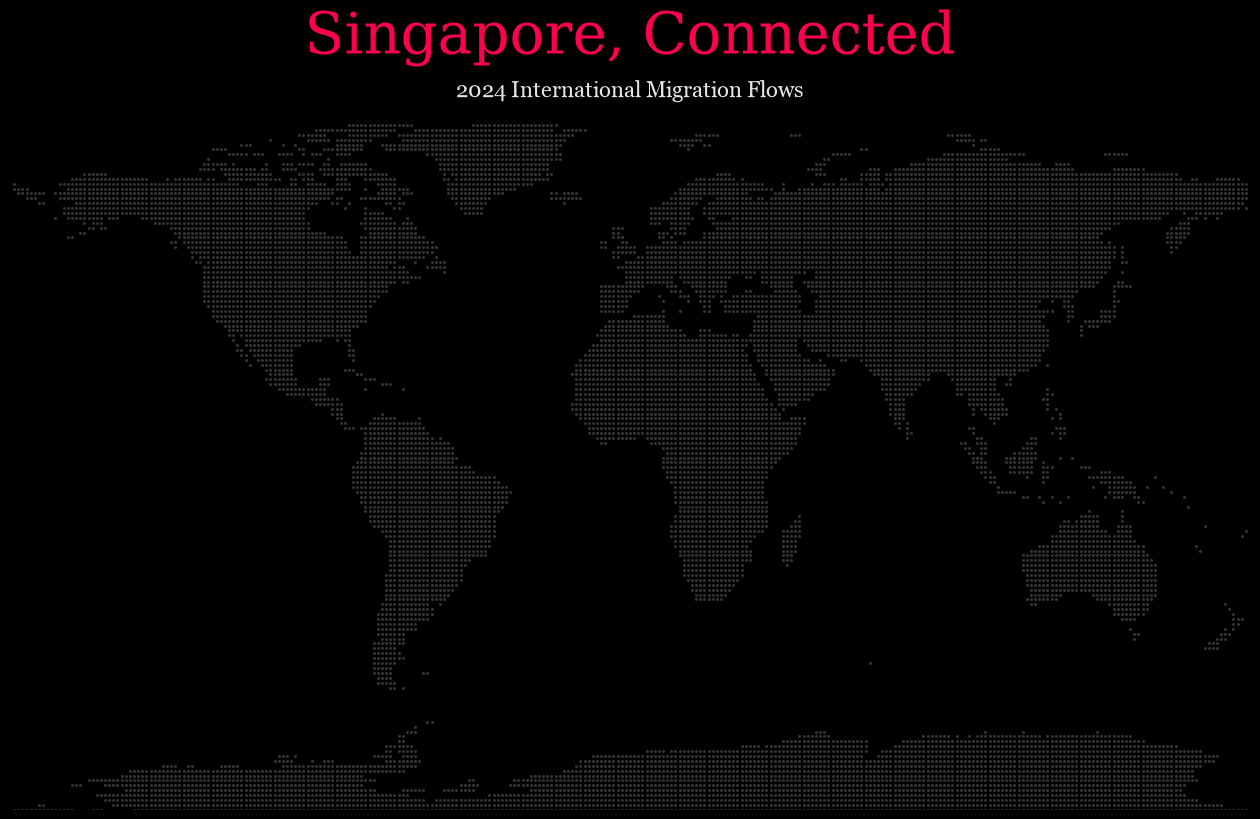

In [152]:
fig, ax = plt.subplots(figsize=(16, 9), facecolor="black")
ax.set_facecolor("black")

# Dotted world map
ax.scatter(
    land_points.geometry.x,
    land_points.geometry.y,
    s=1.5,
    color="#333",
    alpha=1.0
)

# Title
ax.set_title(
    "Singapore, Connected",
    fontsize=42,
    fontweight="light",
    fontfamily="serif",
    color="#FF004C",
    pad=45
)

ax.text(
    0.5, 1.02,
    "2024 International Migration Flows",
    transform=ax.transAxes,
    fontsize=16,
    fontfamily="Georgia",
    color="#E6E6E6",
    ha="center",
    va="bottom"
)


# Map dimensions
ax.set_xlim(-180, 180)
ax.set_ylim(-85, 85)
ax.set_axis_off()

plt.show()

### Prepare migration lines
I'm going to try out MatPlotLib's `FancyArrowPatch` with curved paths.

In [108]:
print(df.columns.tolist())

['destination', 'destination_code', 'origin', 'origin_code', 'population_2024', 'direction', 'percentage', 'origin_lat', 'origin_lon', 'destination_lat', 'destination_lon']


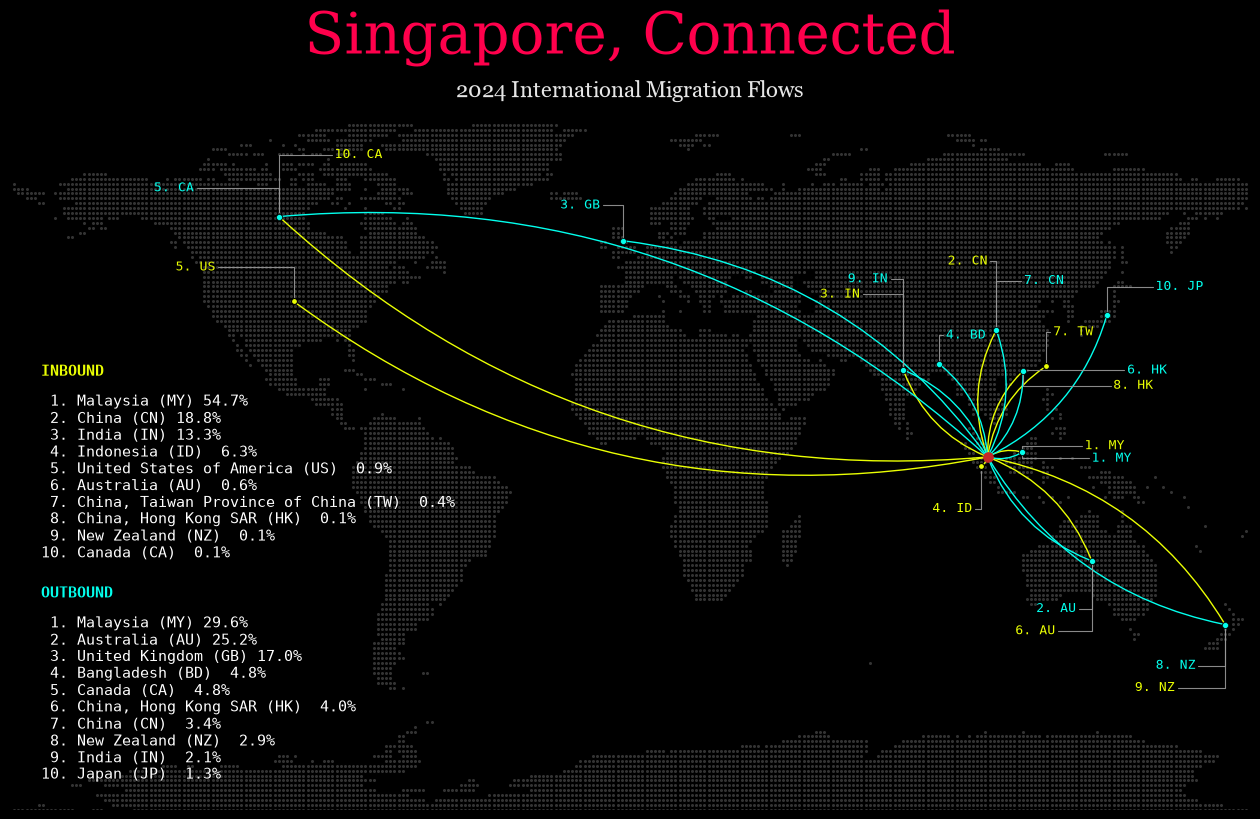

In [336]:
from matplotlib.patches import FancyArrowPatch

fig, ax = plt.subplots(figsize=(16, 9), facecolor="black")
ax.set_facecolor("black")

# Dotted world map
ax.scatter(
    land_points.geometry.x,
    land_points.geometry.y,
    s=1.5,
    color="#333",
    alpha=1.0
)

# ==================
# DRAW MIGRATION ARCS
# ==================

# Draw inbound arcs
for _, row in inbound.iterrows():
    start = (row["origin_lon"], row["origin_lat"])
    end = singapore

    arc = FancyArrowPatch(
        start, end,
        connectionstyle="arc3,rad=0.22",
        arrowstyle="-",
        color="#EAFF03",
        linewidth=1.0,
        alpha=1.0,
        zorder=5
    )
    ax.add_patch(arc)


# Draw outbound arcs
for _, row in outbound.iterrows():
    start = singapore
    end = (row["destination_lon"], row["destination_lat"])

    arc = FancyArrowPatch(
        start, end,
        connectionstyle="arc3,rad=0.22",
        arrowstyle="-",
        color="#03FFED",
        linewidth=1.0,
        alpha=1.0,
        zorder=5
    )
    ax.add_patch(arc)


# ==================
# MARKERS
# ==================

# Inbound endpoint markers
ax.scatter(
    inbound["origin_lon"],
    inbound["origin_lat"],
    s=18,
    color="#EAFF03",
    edgecolors="black",
    linewidths=0.8,
    zorder=12
)

# Outbound endpoint markers
ax.scatter(
    outbound["destination_lon"],
    outbound["destination_lat"],
    s=18,
    color="#03FFED",
    edgecolors="black",
    linewidths=0.4,
    zorder=12
)

# Singapore marker
ax.scatter(
    singapore[0], singapore[1],
    color="#C62828",
    s=45,
    zorder=13
)


# ==================
# HEADERS
# ==================

# Title
ax.set_title(
    "Singapore, Connected",
    fontsize=42,
    fontweight="light",
    fontfamily="serif",
    color="#FF004C",
    pad=45
)

ax.text(
    0.5, 1.02,
    "2024 International Migration Flows",
    transform=ax.transAxes,
    fontsize=16,
    fontfamily="Georgia",
    color="#E6E6E6",
    ha="center",
    va="bottom"
)


# ==================
# COUNTRY LABELS
# ==================

# ISO 3166-1 alpha-2 country codes
country_abbreviations = {
    "United Kingdom": "GB",
    "United States of America": "US",
    "Japan": "JP",
    "China": "CN",
    "New Zealand": "NZ",
    "Australia": "AU",
    "India": "IN",
    "Bangladesh": "BD",
    "China, Hong Kong SAR": "HK",
    "China, Taiwan Province of China": "TW",
    "Malaysia": "MY",
    "Canada": "CA",
    "Indonesia": "ID",
}

# Individual label positions (x, y) in points

inbound_offsets = {
    "Malaysia": (45, 0),
    "China": (-35, 45),
    "India": (-60, 50),
    "Indonesia": (-35, -35),
    "United States of America": (-85, 20),
    "Australia": (-55, -55),
    "China, Taiwan Province of China": (5, 20),
    "China, Hong Kong SAR": (65, -15),
    "New Zealand": (-65, -50),
    "Canada": (40, 40),
}

outbound_offsets = {
    "Malaysia": (50, 0),
    "Australia": (-40, -30),
    "United Kingdom": (-45, 30),
    "Bangladesh": (5, 25),
    "Canada": (-90, 25),
    "China, Hong Kong SAR": (75, 5),
    "China": (20, 40),
    "New Zealand": (-50, -25),
    "India": (-40, 70),
    "Japan": (35, 25),
}


# ==================
# INBOUND ANNOTATIONS
# ==================

inbound_sorted = inbound.sort_values(
    "percentage", ascending=False
).reset_index(drop=True)

for i, row in inbound_sorted.iterrows():

    country = country_abbreviations.get(
        row["origin"], row["origin"]
    )

    label = f"{i + 1}. {country}"

    ax.annotate(
        label,
        xy=(row["origin_lon"], row["origin_lat"]),
        xytext=inbound_offsets.get(row["origin"], (30, 20)),
        textcoords="offset points",
        fontsize=9,
        fontfamily="monospace",
        color="#EAFF03",
        ha="left",
        va="bottom",
        zorder=15,
        arrowprops=dict(
            arrowstyle="-",
            connectionstyle="angle,angleA=0,angleB=90",color="#999",
            linewidth=0.8,
            alpha=0.9,
            shrinkA=0,
            shrinkB=3
        )
    )


# ==================
# OUTBOUND ANNOTATIONS
# ==================

outbound_sorted = outbound.sort_values(
    "percentage", ascending=False
).reset_index(drop=True)

for i, row in outbound_sorted.iterrows():

    country = country_abbreviations.get(
        row["destination"], row["destination"]
    )

    label = f"{i + 1}. {country}"

    ax.annotate(
        label,
        xy=(row["destination_lon"], row["destination_lat"]),
        xytext=outbound_offsets.get(row["destination"], (-30, 20)),
        textcoords="offset points",
        fontsize=9,
        fontfamily="monospace",
        color="#03FFED",
        ha="left",
        va="top",
        zorder=15,
        arrowprops=dict(
            arrowstyle="-",
            connectionstyle="angle,angleA=0,angleB=90",color="#999",
            linewidth=0.8,
            alpha=0.9,
            shrinkA=0,
            shrinkB=3
        )
    )

# ==================
# BOTTOM-LEFT LEGEND
# ==================

def format_legend(data, country_column):

    return "\n".join(
        f"{i + 1:>2}. "
        f"{row[country_column]} "
        f"({country_abbreviations.get(row[country_column], row[country_column])})"
        f"{row['percentage']:>5.1f}%"
        for i, (_, row) in enumerate(data.iterrows())
    )

inbound_legend = format_legend(inbound_sorted, "origin")
outbound_legend = format_legend(outbound_sorted, "destination")


# Inbound header
ax.text(
    0.025, 0.62,
    "INBOUND",
    transform=ax.transAxes,
    fontsize=11,
    fontfamily="monospace",
    fontweight="bold",
    color="#EAFF03",
    ha="left",
    va="bottom",
    zorder=20
)

# Inbound list
ax.text(
    0.025, 0.6,
    inbound_legend,
    transform=ax.transAxes,
    fontsize=11,
    fontfamily="monospace",
    color="white",
    ha="left",
    va="top",
    linespacing=1.1,
    zorder=20
)

# Outbound header
ax.text(
    0.025, 0.3,
    "OUTBOUND",
    transform=ax.transAxes,
    fontsize=11,
    fontfamily="monospace",
    fontweight="bold",
    color="#03FFED",
    ha="left",
    va="bottom",
    zorder=20
)

# Outbound list
ax.text(
    0.025, 0.28,
    outbound_legend,
    transform=ax.transAxes,
    fontsize=11,
    fontfamily="monospace",
    color="white",
    ha="left",
    va="top",
    linespacing=1.1,
    zorder=20
)

ax.set_xlim(-180, 180)
ax.set_ylim(-85, 85)
ax.set_axis_off()

plt.show()